In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Loading the internship dataset
df = pd.read_csv("Dataset.csv")

# Displaying the first five records
display(df.head())

# Checking dataset size
print("Number of rows and columns:", df.shape)

# Displaying column names
print("\nColumn names:")
print(df.columns.tolist())

# Checking missing values
print("\nMissing values:")
print(df.isnull().sum())


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Number of rows and columns: (8790, 10)

Column names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [3]:

# TASK 1: Netflix Content Portfolio Analysis
# Count Movies and TV Shows
content_counts = df["type"].value_counts()
print("Content Distribution:")
print(content_counts)
# Calculate percentages
content_percentages = df["type"].value_counts(normalize=True) * 100
print("\nContent Distribution Percentage:")
print(content_percentages.round(2))
# Create a summary table
content_summary = pd.DataFrame({
    "Content Type": content_counts.index,
    "Total Titles": content_counts.values,
    "Percentage": content_percentages.values.round(2)
})
display(content_summary)


Content Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Content Distribution Percentage:
type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


,Content Type,Total Titles,Percentage
0,Movie,6126,69.69
1,TV Show,2664,30.31


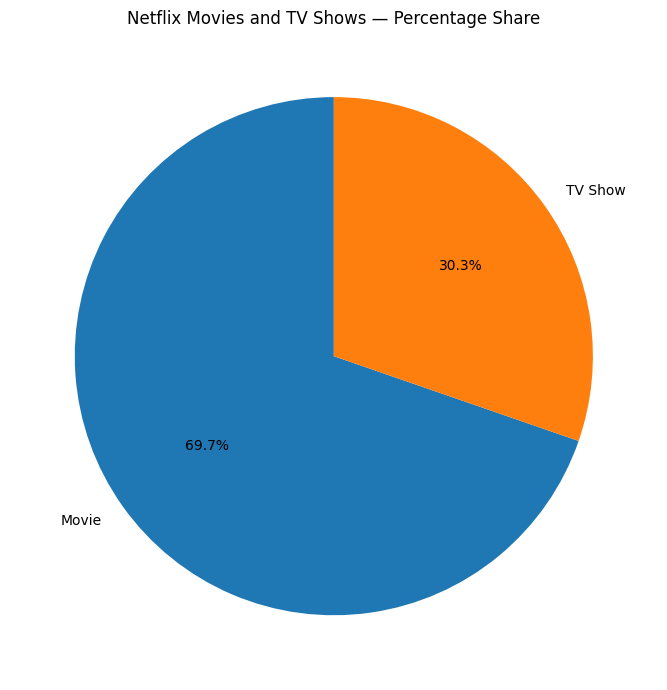

In [4]:

# Pie chart: Content percentage distribution
plt.figure(figsize=(7, 7))
plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90)
plt.title("Netflix Movies and TV Shows — Percentage Share")
plt.tight_layout()
plt.show()


In [5]:

# TASK 2: Global Market Performance Analysis
# Split country values where multiple countries are listed
country_data = (
    df[["show_id", "title", "type", "country"]]
    .dropna(subset=["country"])
    .assign(country=lambda x: x["country"].str.split(","))
    .explode("country"))
# Removeing extra spaces
country_data["country"] = country_data["country"].str.strip()
# Counting titles per country without counting the same title-country twice
country_data = country_data.drop_duplicates(
    subset=["show_id", "country"])
country_counts = country_data["country"].value_counts()
print("Total countries represented:", country_counts.size)
print("\nTop 10 countries by title count:")
display(country_counts.head(10).rename("Title Count").to_frame())


Total countries represented: 86

Top 10 countries by title count:


,Title Count
country,
United States,3240
India,1057
United Kingdom,638
Pakistan,421
Not Given,287
Canada,271
Japan,259
South Korea,214
France,213


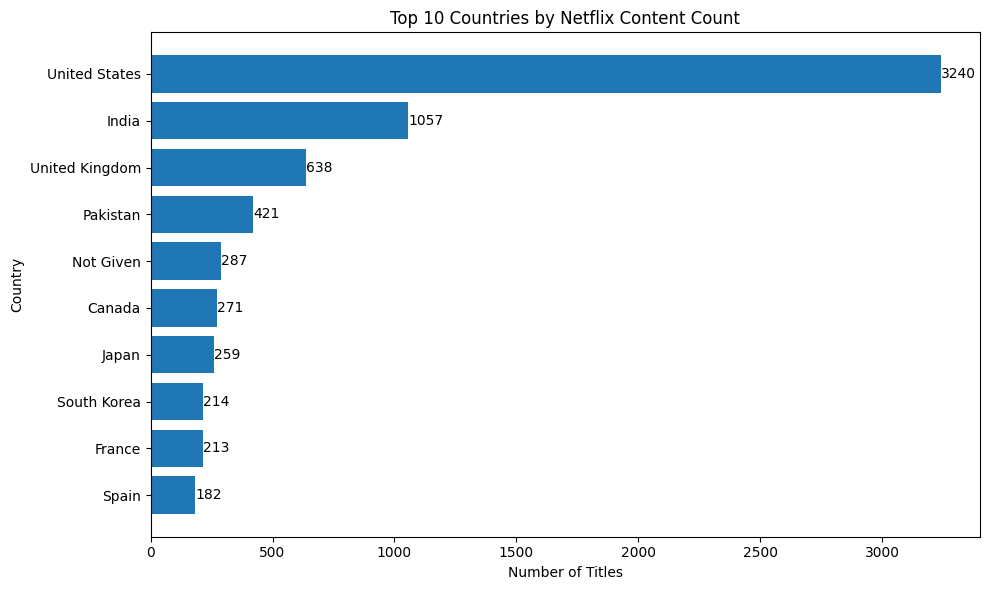

In [6]:

top_countries = country_counts.head(10).sort_values()
plt.figure(figsize=(10, 6))
bars = plt.barh(
    top_countries.index,
    top_countries.values)
plt.bar_label(bars)
plt.title("Top 10 Countries by Netflix Content Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [7]:

# TASK 3: Audience Segmentation Analysis
# Count titles by rating
rating_counts = df["rating"].value_counts()
print("Content distribution by rating:")
display(rating_counts.rename("Title Count").to_frame())
# Compare ratings between Movies and TV Shows
rating_comparison = pd.crosstab(
    df["rating"],
    df["type"])
print("\nRating comparison by content type:")
display(rating_comparison)


Content distribution by rating:


,Title Count
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220



Rating comparison by content type:


type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143


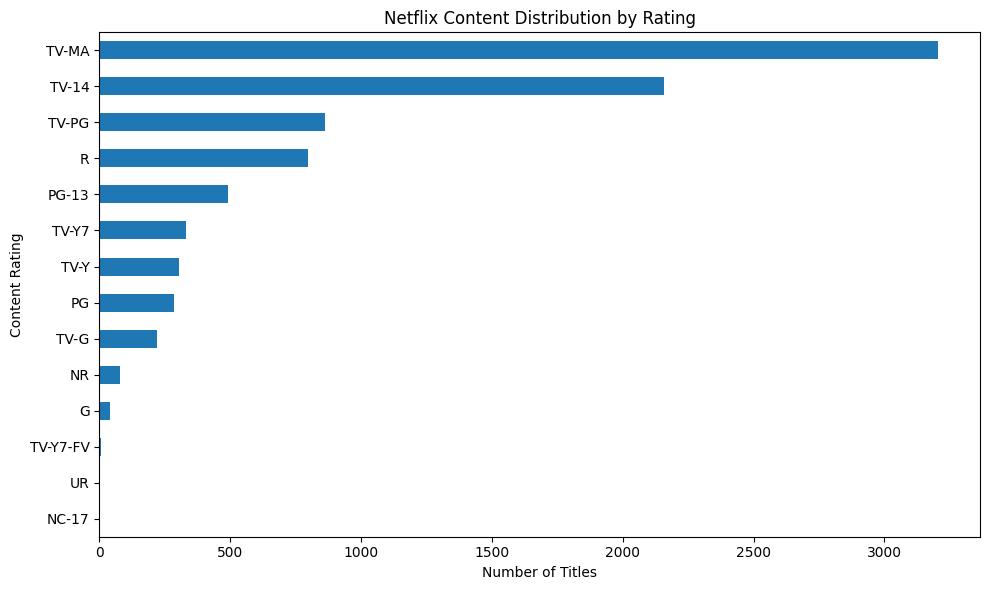

In [8]:

plt.figure(figsize=(10, 6))

rating_counts.sort_values().plot(kind="barh")

plt.title("Netflix Content Distribution by Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()


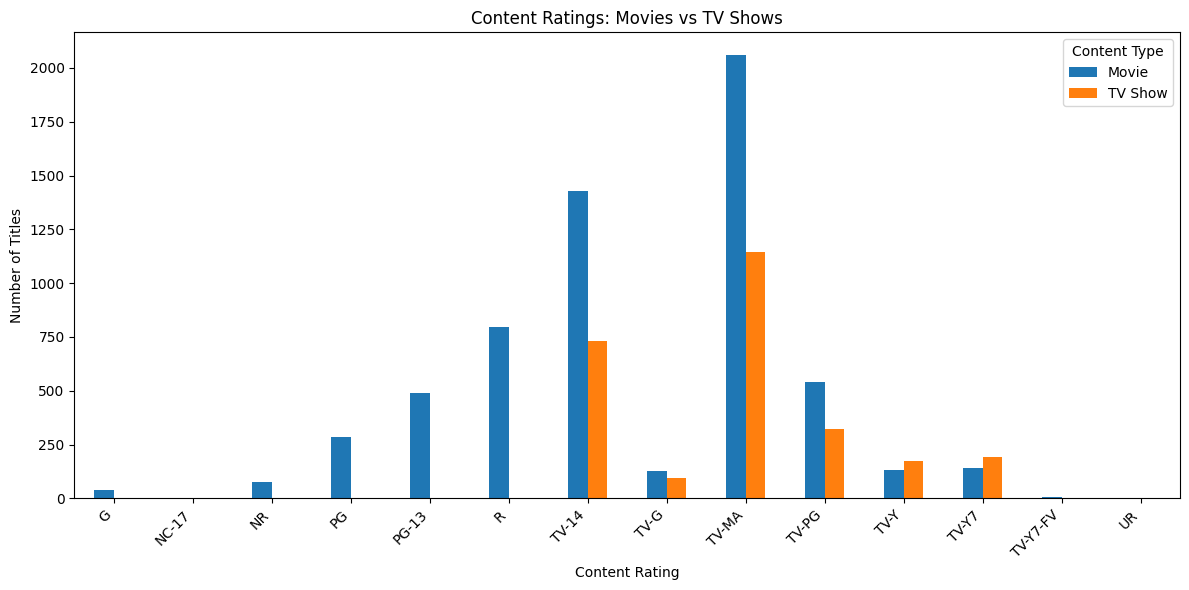

In [10]:

rating_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


In [11]:

# TASK 4: Content Growth and Trend Analysis
# Count titles released in each year
yearly_content = df["release_year"].value_counts().sort_index()
print("Latest release years:")
display(yearly_content.tail(15).rename("Title Count").to_frame())
# Identify years with the highest number of titles
print("\nTop 10 release years:")
display(
    yearly_content.sort_values(ascending=False)
    .head(10)
    .rename("Title Count")
    .to_frame()
)


Latest release years:


,Title Count
release_year,
2007,88
2008,135
2009,152
2010,192
2011,185
2012,236
2013,286
2014,352
2015,555



Top 10 release years:


,Title Count
release_year,
2018,1146
2017,1030
2019,1030
2020,953
2016,901
2021,592
2015,555
2014,352
2013,286


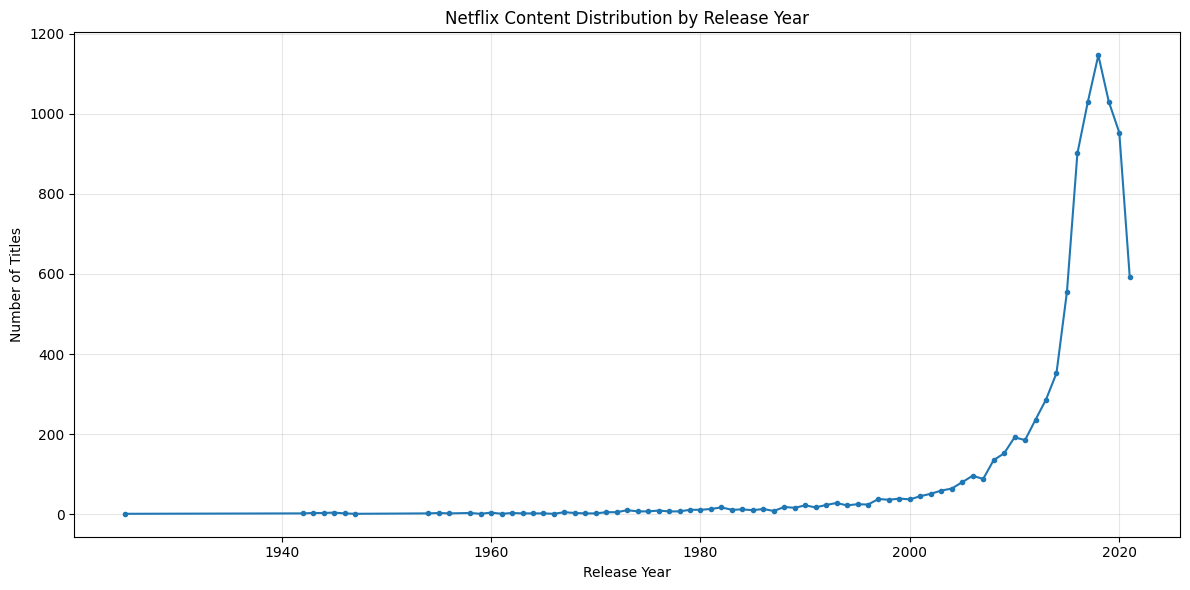

In [12]:

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_content.index,
    yearly_content.values,
    marker="o",
    markersize=3
)

plt.title("Netflix Content Distribution by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Titles added to the catalogue by year:


,Titles Added
added_year,
2008,2
2009,2
2010,1
2011,13
2012,3
2013,11
2014,24
2015,82
2016,426


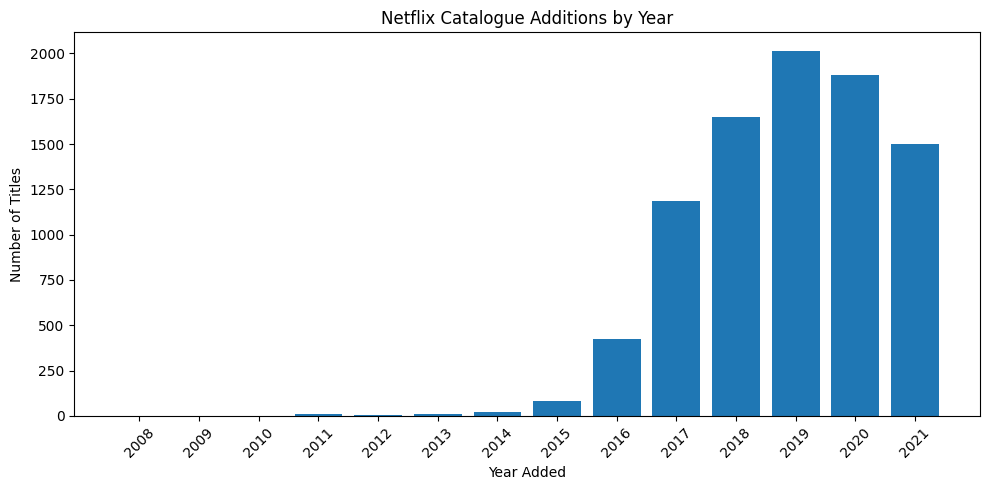

In [13]:

# Convert date_added to a proper date format
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce")
# Counting titles added each year
added_yearly = (
    df.dropna(subset=["date_added"])
    .assign(added_year=lambda x: x["date_added"].dt.year)
    .groupby("added_year")["show_id"]
    .nunique())
print("Titles added to the catalogue by year:")
display(added_yearly.rename("Titles Added").to_frame())
# Ploting catalogue additions
plt.figure(figsize=(10, 5))
plt.bar(added_yearly.index.astype(str), added_yearly.values)
plt.title("Netflix Catalogue Additions by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
